# Lab 09 — Tokenizer & Label Alignment

Phân tích hiện tượng phân tách subwords và chiến lược căn chỉnh nhãn (label alignment) trên CoNLL-2003.

In [1]:
from datasets import load_dataset
from transformers import AutoTokenizer

ds = load_dataset('lhoestq/conll2003')
tokenizer = AutoTokenizer.from_pretrained('bert-base-cased')

sample = ds['train'][0]
print("Tokens:  ", sample['tokens'])
print("NER Tags:", sample['ner_tags'])

Tokens:   ['EU', 'rejects', 'German', 'call', 'to', 'boycott', 'British', 'lamb', '.']
NER Tags: [3, 0, 7, 0, 0, 0, 7, 0, 0]


## 1. Subword Tokenization & Alignment Problem

In [2]:
words = ["Washington", "playing", "UNICEF", "1996-12-06", "newcomers"]
for w in words:
    subwords = tokenizer.tokenize(w)
    print(f"{w:15s} -> {subwords}")

Washington      -> ['Washington']
playing         -> ['playing']
UNICEF          -> ['UN', '##IC', '##EF']
1996-12-06      -> ['1996', '-', '12', '-', '06']
newcomers       -> ['newcomer', '##s']


## 2. Alignment Strategies (Strategy A vs Strategy B)

In [3]:
tag_names = ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
sample_tokens = ds['train'][0]['tokens']
sample_tags = [tag_names[t] for t in ds['train'][0]['ner_tags']]

enc = tokenizer(sample_tokens, is_split_into_words=True, return_tensors=None)
subwords = tokenizer.convert_ids_to_tokens(enc['input_ids'])
word_ids = enc.word_ids()

# Strategy A: First subword receives word tag, subsequent receive -100
strat_a_labels = []
prev = None
for wid in word_ids:
    if wid is None:
        strat_a_labels.append(-100)
    elif wid != prev:
        strat_a_labels.append(sample_tags[wid])
    else:
        strat_a_labels.append(-100)
    prev = wid

# Strategy B: Propagate tag
strat_b_labels = []
prev = None
for wid in word_ids:
    if wid is None:
        strat_b_labels.append('O')
    elif wid != prev:
        strat_b_labels.append(sample_tags[wid])
    else:
        orig = sample_tags[wid]
        strat_b_labels.append(f"I-{orig[2:]}" if orig.startswith('B-') else orig)
    prev = wid

print(f"{'Subword':<12} {'Word ID':<10} {'Strategy A':<15} {'Strategy B'}")
print("-" * 50)
for sw, wid, sa, sb in zip(subwords, word_ids, strat_a_labels, strat_b_labels):
    print(f"{sw:<12} {str(wid):<10} {str(sa):<15} {sb}")

Subword      Word ID    Strategy A      Strategy B
--------------------------------------------------
[CLS]        None       -100            O
EU           0          B-ORG           B-ORG
rejects      1          O               O
German       2          B-MISC          B-MISC
call         3          O               O
to           4          O               O
boycott      5          O               O
British      6          B-MISC          B-MISC
la           7          O               O
##mb         7          -100            O
.            8          O               O
[SEP]        None       -100            O


## 3. Loss Masking with Ignore Index (-100)

In [4]:
import torch
import torch.nn as nn

loss_fn = nn.CrossEntropyLoss(ignore_index=-100)
logits = torch.randn(1, len(strat_a_labels), 9)
targets = torch.tensor([tag_names.index(l) if l != -100 else -100 for l in strat_a_labels]).unsqueeze(0)

loss = loss_fn(logits.view(-1, 9), targets.view(-1))
print("Computed loss (ignoring -100):", round(loss.item(), 4))

Computed loss (ignoring -100): 1.9963


## 4. Experiment 1: Tokenization Statistics

Overall average R (tokens/words): 1.5663
Sentences with entities R:        1.6208
Sentences without entities R:     1.2316


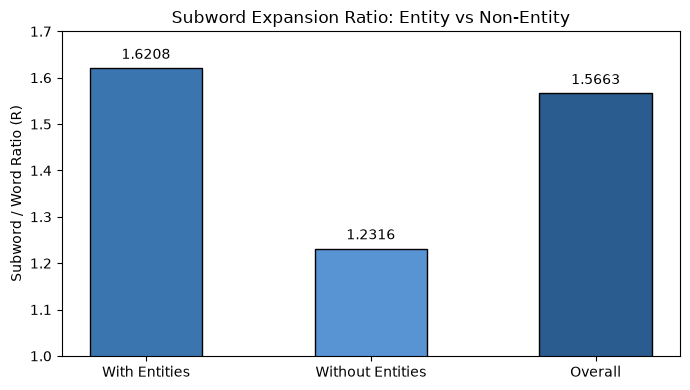

In [5]:
import matplotlib.pyplot as plt
import numpy as np

tok_stats = []
for i in range(100):
    ex = ds['test'][i]
    w = ex['tokens']
    enc = tokenizer(w, is_split_into_words=True)
    n_w = len(w)
    n_t = sum(1 for wid in enc.word_ids() if wid is not None)
    ratio = n_t / n_w if n_w > 0 else 1.0
    has_ent = any(t != 0 for t in ex['ner_tags'])
    tok_stats.append({'ratio': ratio, 'has_entity': has_ent, 'words': n_w, 'tokens': n_t})

r_all = [s['ratio'] for s in tok_stats]
r_ent = [s['ratio'] for s in tok_stats if s['has_entity']]
r_no_ent = [s['ratio'] for s in tok_stats if not s['has_entity']]

print(f"Overall average R (tokens/words): {np.mean(r_all):.4f}")
print(f"Sentences with entities R:        {np.mean(r_ent):.4f}")
print(f"Sentences without entities R:     {np.mean(r_no_ent):.4f}")

plt.figure(figsize=(7, 4))
plt.bar(['With Entities', 'Without Entities', 'Overall'], [np.mean(r_ent), np.mean(r_no_ent), np.mean(r_all)],
        color=['#3b75af', '#5893d4', '#2b5c8f'], edgecolor='black', width=0.5)
plt.ylabel('Subword / Word Ratio (R)')
plt.title('Subword Expansion Ratio: Entity vs Non-Entity')
plt.ylim(1.0, 1.7)
for i, v in enumerate([np.mean(r_ent), np.mean(r_no_ent), np.mean(r_all)]):
    plt.text(i, v + 0.02, f"{v:.4f}", ha='center', fontsize=10)
plt.tight_layout()
plt.show()